## Introduction

In [26]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import wbgapi as wb
import os
import requests
plt.style.use('ggplot')

## Datasets

In [27]:
def fetch_world_bank_data(indicators, time_range):
    print("Fetching data from World Bank API...")
    df = wb.data.DataFrame(
        series=indicators.keys(), 
        time=time_range, 
        labels=True, 
        columns='series' 
    ).reset_index()
    
    # Rename columns for clarity
    df = df.rename(columns={'economy': 'Country_Code', 'Country': 'Country_Name', 'time': 'Year'})
    df = df.rename(columns=indicators)
    df = df.drop(columns='Time')
    df['Year'] = df['Year'].str.replace('YR', '').astype(int)
    
    return df

def fetch_imf_data(imf_indicators, time_range):
    base_url = "https://www.imf.org/external/datamapper/api/v1"
    target_years = set(map(str, time_range))
    imf_df = None

    for code, col_name in imf_indicators.items():
        url = f"{base_url}/{code}"
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        data = response.json()

        # Navigate JSON structure: values -> indicator_code -> country_code -> year
        country_dict = data.get('values', {}).get(code, {})
        records = []

        for country_code, years_data in country_dict.items():
            for year_str, value in years_data.items():
                if year_str in target_years:
                    records.append({
                        'Country_Code': country_code,
                        'Year': int(year_str),
                        col_name: pd.to_numeric(value, errors='coerce')
                    })

        df_indicator = pd.DataFrame(records)
        if imf_df is None:
            imf_df = df_indicator
        else:
            imf_df = pd.merge(imf_df, df_indicator, on=['Country_Code', 'Year'], how='outer')

    return imf_df

if (os.path.isfile('all_countries_data.csv') and os.path.isfile('imf_secondary_data.csv')):
    print('reading CSV.....')
    df = pd.read_csv('all_countries_data.csv', delimiter=',')
    df_imf = pd.read_csv('imf_secondary_data.csv', delimiter=',')
    
else:
    # define the specific World Bank Series Codes
    indicators = {
        'IT.NET.USER.ZS': 'Internet_Usage_Pct',
        'SE.SEC.CMPT.LO.ZS': 'Lower_Sec_Completion_Pct',
        'NY.ADJ.NNTY.PC.CD': 'Income_Per_Capita_USD',
        'EG.ELC.ACCS.ZS': 'Electricity_Access_Pct',
    }

    imf_indicators = {
        'PCPIPCH': 'Inflation_Rate_Pct',    
        'LUR': 'Unemployment_Rate_Pct'  
    }
    
    time_range = range(2013, 2024)

    print("Fetching data API")
    df = fetch_world_bank_data(indicators, time_range)
    df_imf = fetch_imf_data(imf_indicators, time_range)

    #save to csv
    df_imf.to_csv('imf_secondary_data.csv', index=False)
    df.to_csv('all_countries_data.csv', index=False)

    #renaming
    df = df.rename(columns={'economy': 'Country_Code', 'Country': 'Country_Name', 'time': 'Year'})
    df = df.rename(columns=indicators)
    df = df.drop(columns='Time')
    df['Year'] = df['Year'].str.replace('YR', '').astype(int)

    print("\nData fetched successfully!")

print(df.info())




reading CSV.....
<class 'pandas.DataFrame'>
RangeIndex: 2926 entries, 0 to 2925
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Country_Code              2926 non-null   str    
 1   Year                      2926 non-null   int64  
 2   Country_Name              2926 non-null   str    
 3   Electricity_Access_Pct    2893 non-null   float64
 4   Internet_Usage_Pct        2456 non-null   float64
 5   Income_Per_Capita_USD     2020 non-null   float64
 6   Lower_Sec_Completion_Pct  1949 non-null   float64
dtypes: float64(4), int64(1), str(2)
memory usage: 205.0 KB
None


## Data Preprocessing

717
551


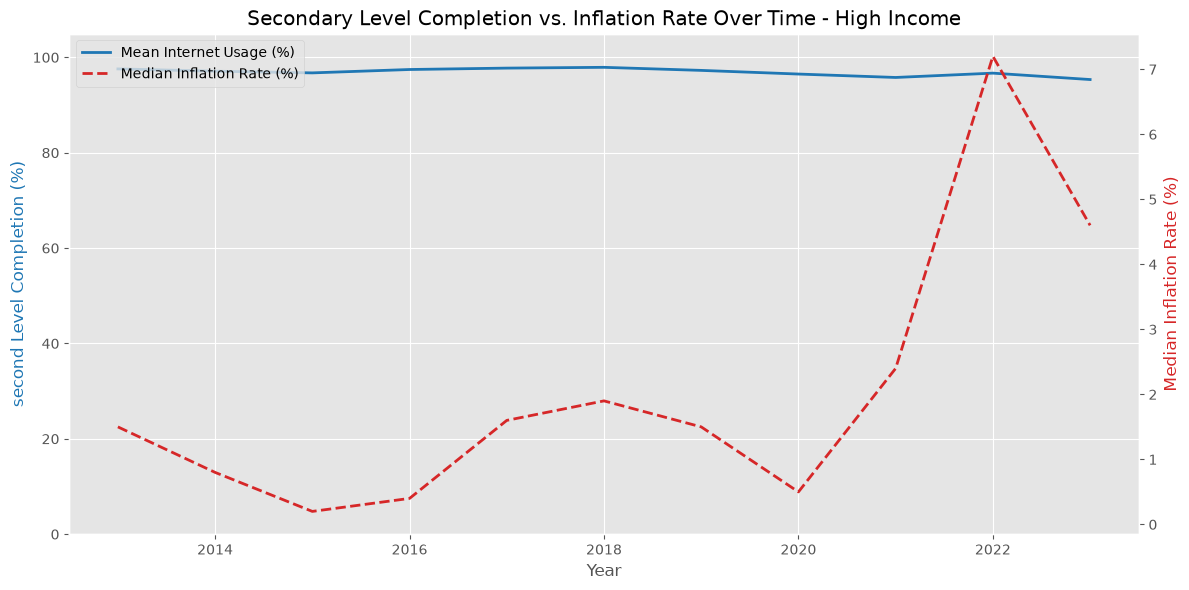

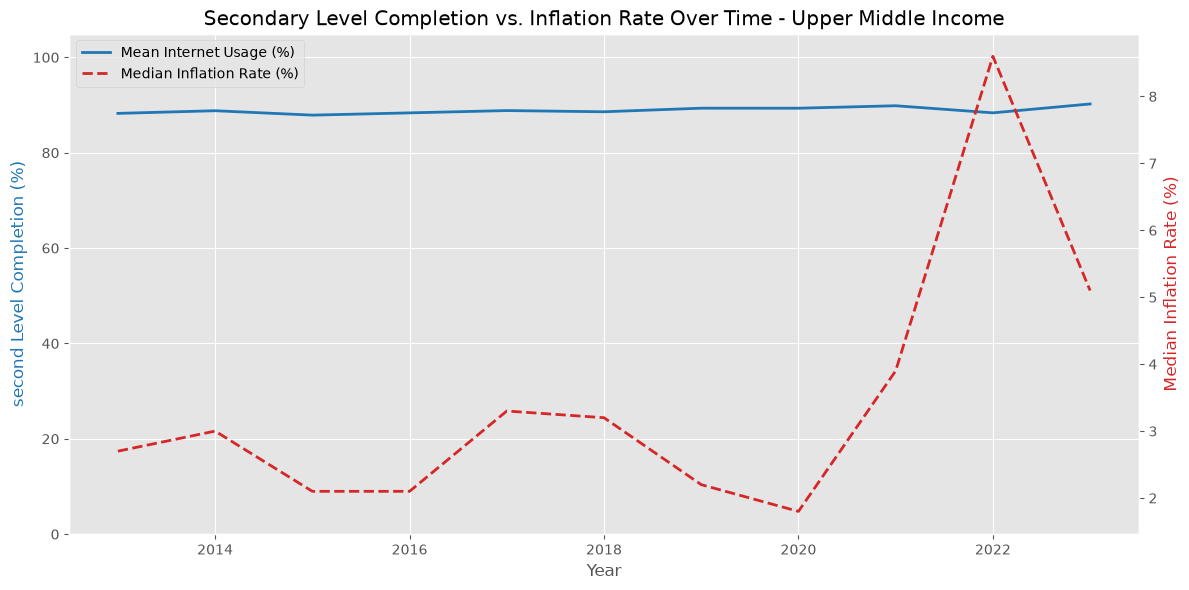

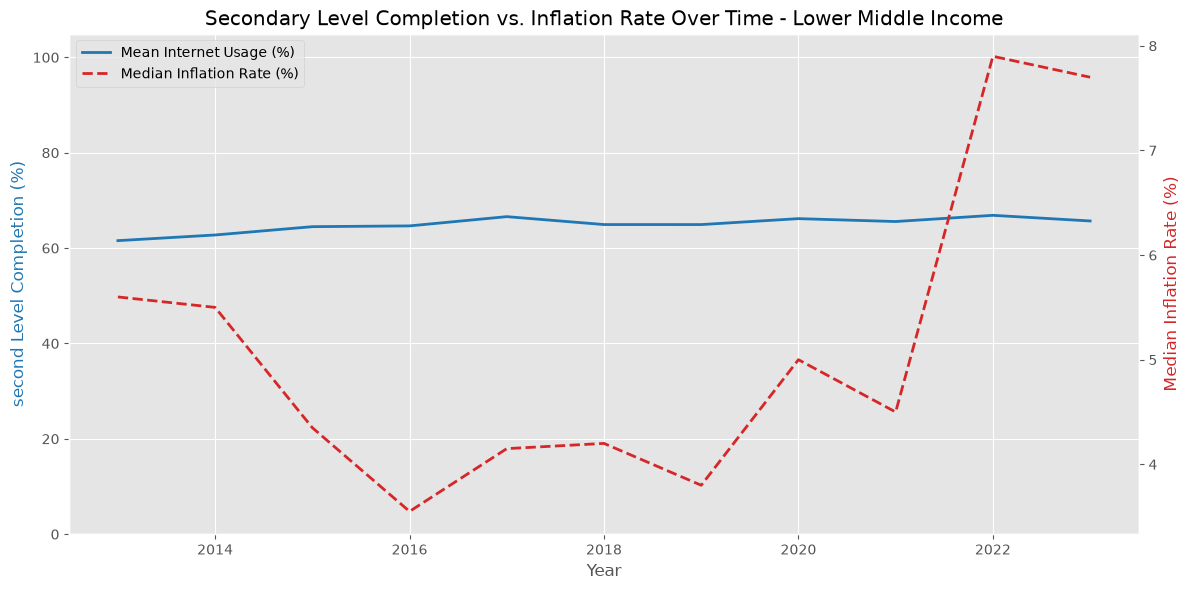

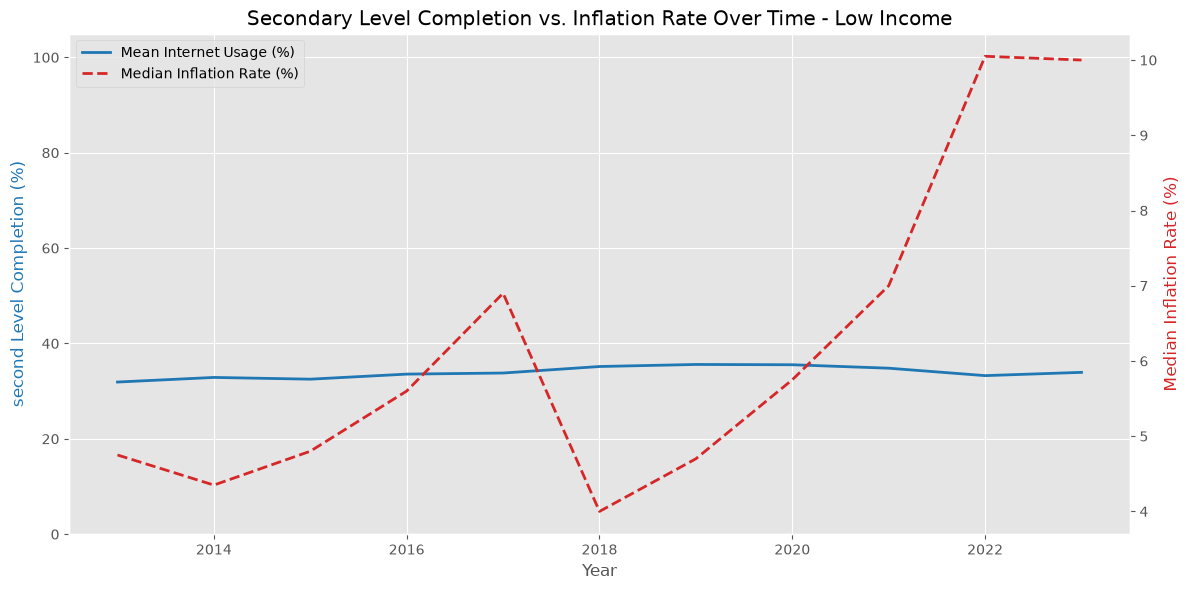

In [ ]:
#grab economic data from World bank
countries = wb.economy.DataFrame()
sovereign_countries = countries[countries['aggregate'] == False]
sovereign_codes = sovereign_countries.index

# filter to only sovereign countries
df = df[df['Country_Code'].isin(sovereign_codes)]

income_map = sovereign_countries['incomeLevel'].to_dict()

# map income code onto main df
df['Income_Level_Code'] = df['Country_Code'].map(income_map)

# create readable mapping for income levels
income_names = {
    'HIC': 'High Income',
    'UMC': 'Upper Middle Income',
    'LMC': 'Lower Middle Income',
    'LIC': 'Low Income',
    'INX': 'Not Classified'
}

#map codes to readable levels
df['Income_Level'] = df['Income_Level_Code'].map(income_names)

df = df.drop(columns='Income_Level_Code')

# drop not classified in order to keep analysis clean and focused on classified income levels
df = df[df['Income_Level'] != 'Not Classified']

# merge IMF data with World Bank data
df = pd.merge(df, df_imf, on=['Country_Code', 'Year'], how='inner')

print(df['Lower_Sec_Completion_Pct'].isnull().sum())

print(df['Income_Per_Capita_USD'].isnull().sum())

# impute values to median of coresponding income level
df['Lower_Sec_Completion_Pct'] = df['Lower_Sec_Completion_Pct'].fillna(df.groupby('Income_Level')['Lower_Sec_Completion_Pct'].transform('median'))
df['Income_Per_Capita_USD'] = df['Income_Per_Capita_USD'].fillna(df.groupby('Income_Level')['Income_Per_Capita_USD'].transform('median'))
df['Electricity_Access_Pct'] = df['Electricity_Access_Pct'].fillna(df.groupby('Income_Level')['Electricity_Access_Pct'].transform('median'))
df['Internet_Usage_Pct'] = df['Internet_Usage_Pct'].fillna(df.groupby('Income_Level')['Internet_Usage_Pct'].transform('median'))

# impute merged values to median of coresponding income level
df['Inflation_Rate_Pct'] = df['Inflation_Rate_Pct'].fillna(df.groupby('Income_Level')['Inflation_Rate_Pct'].transform('median'))
df['Unemployment_Rate_Pct'] = df['Unemployment_Rate_Pct'].fillna(df.groupby('Income_Level')['Unemployment_Rate_Pct'].transform('median'))

## Data Analysis

In [ ]:
income_order = ['High Income', 'Upper Middle Income', 'Lower Middle Income', 'Low Income']

for level in income_order:
    subset = df[df['Income_Level'] == level]
    if subset.empty:
        continue

    fig, ax1 = plt.subplots(figsize=(12, 6))
    yearly_internet = subset.groupby('Year')['Lower_Sec_Completion_Pct'].mean()
    line1 = ax1.plot(
        yearly_internet.index, yearly_internet.values,
        color='tab:blue', linewidth=2, label='Mean Internet Usage (%)'
    )
    ax1.set_xlabel('Year')
    ax1.set_ylabel('second Level Completion (%)', color='tab:blue')
    ax1.set_ylim(0, 105)

    ax2 = ax1.twinx()
    yearly_inflation = subset.groupby('Year')['Inflation_Rate_Pct'].median()
    line2 = ax2.plot(
        yearly_inflation.index, yearly_inflation.values,
        color='tab:red', linestyle='--', linewidth=2, label='Median Inflation Rate (%)'
    )
    ax2.set_ylabel('Median Inflation Rate (%)', color='tab:red')
    ax2.grid(False)

    lines = line1 + line2
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='upper left')

    plt.title(f'Secondary Level Completion vs. Inflation Rate Over Time - {level}')
    plt.tight_layout()
    plt.show()

## Visualization

## Discussion

## Conclusion

## Reflection

## AI Use statement